In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn plotly mplcursors

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================
# MNIST PCA VISUAL DASHBOARD
# Imports and configuration
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score

from IPython.display import display, Markdown

# Interactive hover support
import mplcursors

# Plot configuration
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Environment is ready for PCA analysis.")

Libraries imported successfully!
Environment is ready for PCA analysis.


In [3]:
# ============================================================
# LOAD MNIST DATASET
# ============================================================

def load_mnist_data():
    """
    Load the MNIST handwritten digit dataset.

    Returns
    -------
    X : numpy.ndarray
        Pixel feature matrix.
    y : numpy.ndarray
        Digit labels.
    """
    try:
        print("Loading MNIST dataset from OpenML...")

        mnist = fetch_openml(
            "mnist_784",
            version=1,
            as_frame=False
        )

        X = mnist.data
        y = mnist.target.astype(int)

        print("Dataset loaded successfully using OpenML.")

    except Exception as openml_error:
        print("OpenML loading failed.")
        print("Trying TensorFlow/Keras dataset loader...")

        try:
            from tensorflow.keras.datasets import mnist as keras_mnist

            (X_train, y_train), (X_test, y_test) = keras_mnist.load_data()

            X = np.concatenate([X_train, X_test], axis=0)
            y = np.concatenate([y_train, y_test], axis=0)

            X = X.reshape(X.shape[0], -1)

            print("Dataset loaded successfully using Keras.")

        except Exception as keras_error:
            raise RuntimeError(
                "Unable to load MNIST. Check your internet connection "
                "and install TensorFlow if the fallback is needed."
            ) from keras_error

    return X, y


X_raw, y = load_mnist_data()

print("\nDataset shape:", X_raw.shape)
print("Labels shape:", y.shape)
print("Number of classes:", np.unique(y).size)
print("Classes:", np.unique(y))

Loading MNIST dataset from OpenML...
Dataset loaded successfully using OpenML.

Dataset shape: (70000, 784)
Labels shape: (70000,)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


Number of samples: 70000
Number of pixel features: 784
Unique digit labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


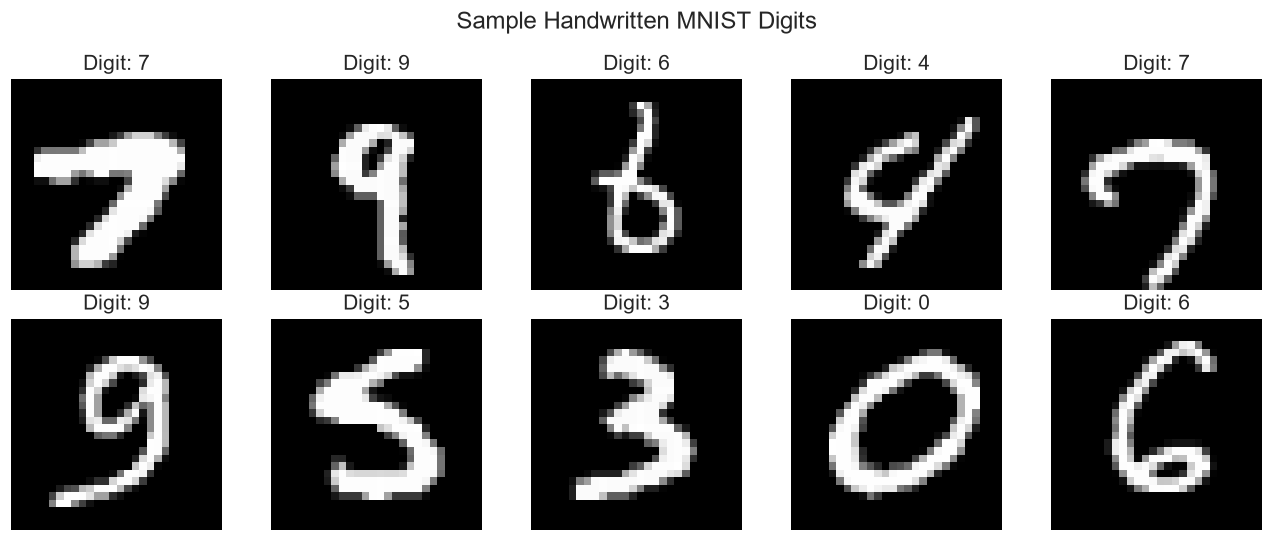

In [4]:
# ============================================================
# DATASET OVERVIEW
# ============================================================

print("Number of samples:", len(X_raw))
print("Number of pixel features:", X_raw.shape[1])
print("Unique digit labels:", sorted(np.unique(y).tolist()))

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

sample_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_raw), size=10, replace=False
)

for ax, idx in zip(axes.flatten(), sample_indices):
    ax.imshow(X_raw[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Digit: {y[idx]}")
    ax.axis("off")

plt.suptitle("Sample Handwritten MNIST Digits", fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# DATA PREPROCESSING AND STANDARDIZATION
# ============================================================

SAMPLE_SIZE = 10000

# Stratified sampling preserves the distribution of digit labels
X_sample, _, y_sample, _ = train_test_split(
    X_raw,
    y,
    train_size=SAMPLE_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

# Convert to float for numerical calculations
X_sample = X_sample.astype(np.float32)

# Standardize pixel features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_sample)

print("Original sampled data shape:", X_sample.shape)
print("Standardized data shape:", X_scaled.shape)
print("Mean of standardized features:", round(float(X_scaled.mean()), 4))
print("Standardization completed successfully.")

Original sampled data shape: (10000, 784)
Standardized data shape: (10000, 784)
Mean of standardized features: 0.0
Standardization completed successfully.


In [6]:
# ============================================================
# PRINCIPAL COMPONENT ANALYSIS
# ============================================================

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for visualization and analysis
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Digit": y_sample.astype(int)
})

print("PCA transformation completed!")
print("Reduced data shape:", X_pca.shape)
print("\nExplained variance ratio:")
print(f"PC1: {pca.explained_variance_ratio_[0]:.4%}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.4%}")
print(
    "Total variance retained by 2 components:",
    f"{pca.explained_variance_ratio_.sum():.4%}"
)

display(pca_df.head())

PCA transformation completed!
Reduced data shape: (10000, 2)

Explained variance ratio:
PC1: 5.9004%
PC2: 4.2419%
Total variance retained by 2 components: 10.1423%


,PC1,PC2,Digit
0,-8.016984,-1.128708,1
1,-3.633304,-6.174441,5
2,-3.024227,0.619354,8
3,6.710340,-0.145647,2
4,0.581021,-4.294485,5


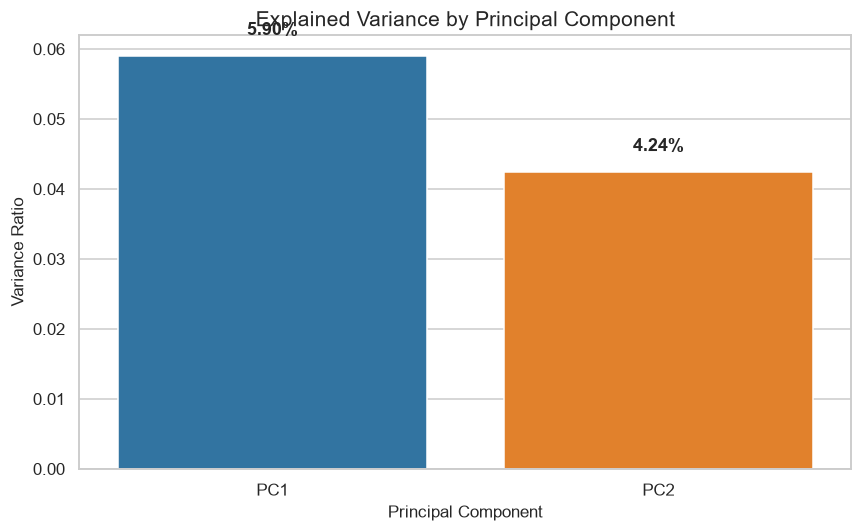

In [7]:
# ============================================================
# EXPLAINED VARIANCE VISUALIZATION
# ============================================================

variance_data = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance": pca.explained_variance_ratio_
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=variance_data,
    x="Component",
    y="Explained Variance",
    hue="Component",
    legend=False
)

plt.title("Explained Variance by Principal Component")
plt.ylabel("Variance Ratio")
plt.xlabel("Principal Component")

for i, value in enumerate(pca.explained_variance_ratio_):
    plt.text(
        i,
        value + 0.003,
        f"{value:.2%}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

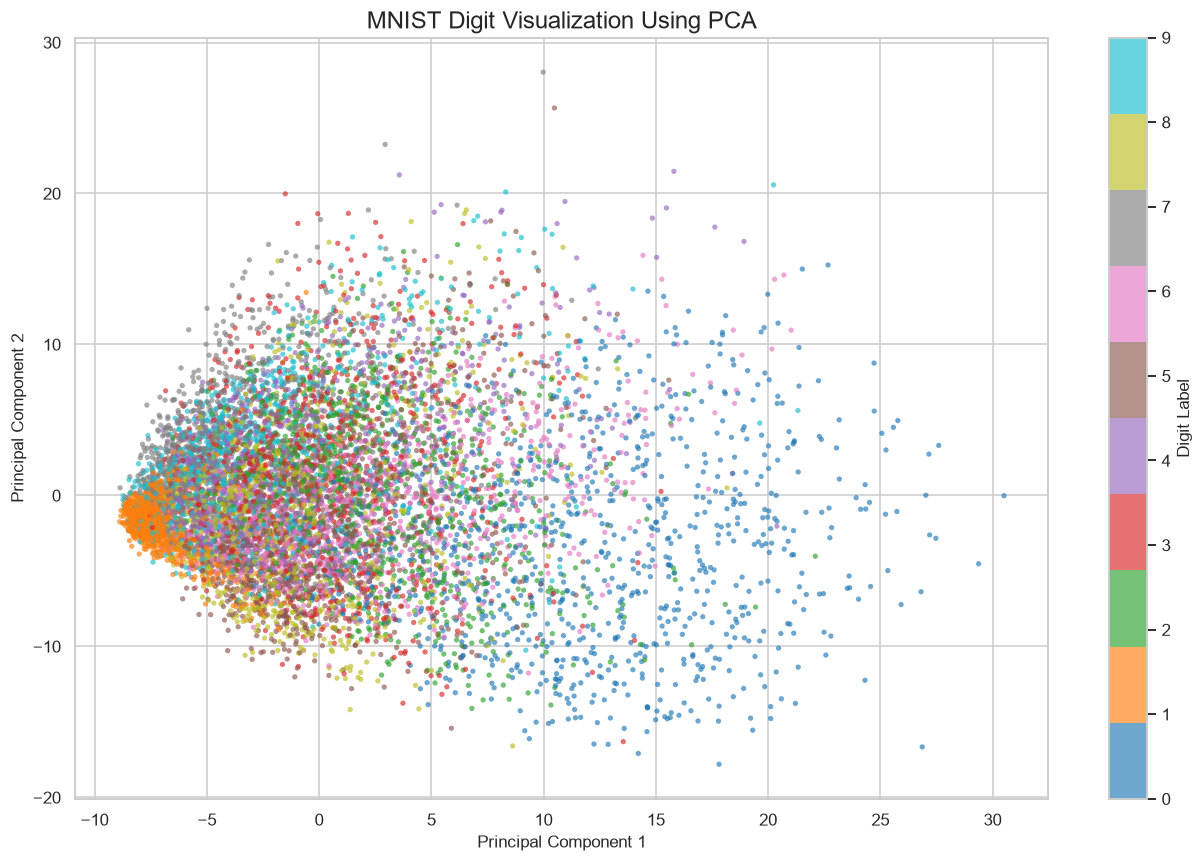

In [8]:
# ============================================================
# PCA SCATTER PLOT
# ============================================================

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Digit"],
    cmap="tab10",
    s=12,
    alpha=0.65,
    edgecolors="none"
)

colorbar = plt.colorbar(scatter, ticks=range(10))
colorbar.set_label("Digit Label")

plt.title("MNIST Digit Visualization Using PCA", fontsize=16)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

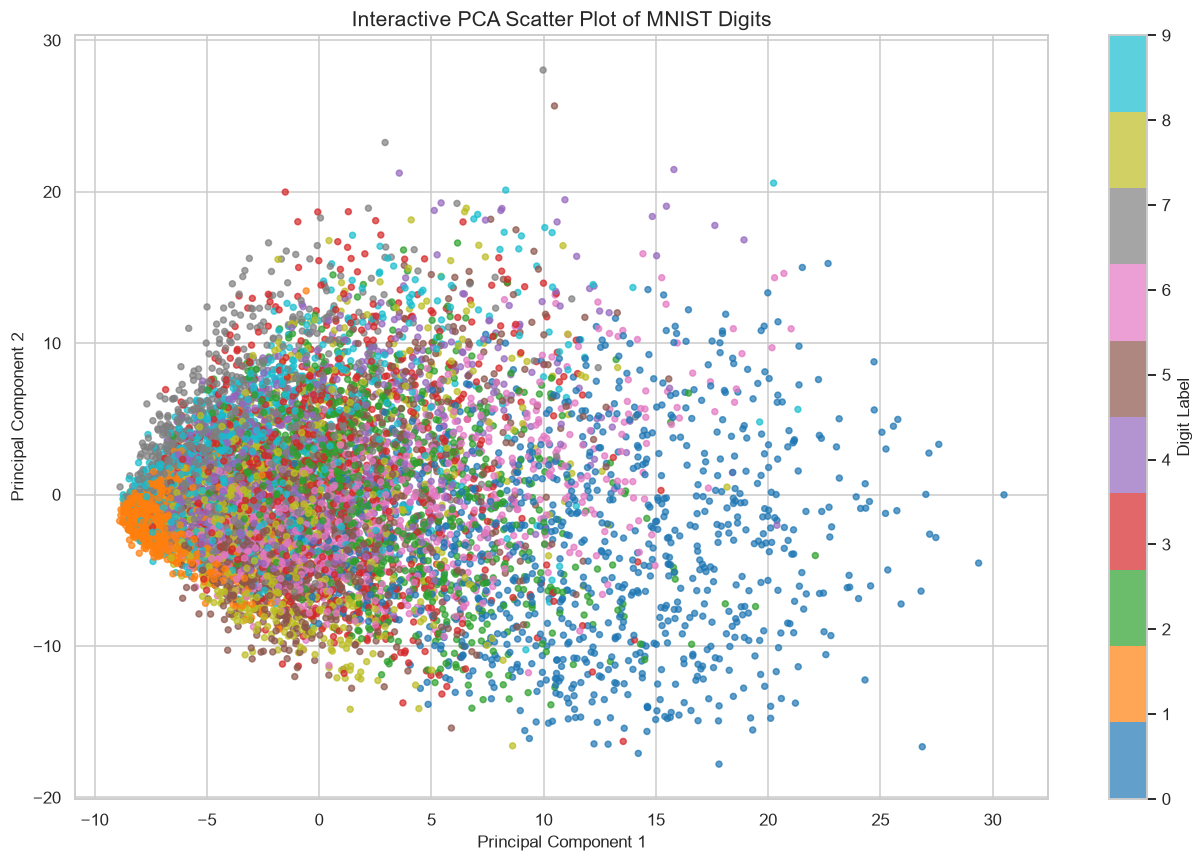

In [9]:
# ============================================================
# INTERACTIVE PCA SCATTER WITH HOVER INFORMATION
# ============================================================

fig, ax = plt.subplots(figsize=(12, 8))

scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Digit"],
    cmap="tab10",
    s=15,
    alpha=0.7
)

ax.set_title("Interactive PCA Scatter Plot of MNIST Digits")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

cbar = plt.colorbar(scatter, ax=ax, ticks=range(10))
cbar.set_label("Digit Label")

# Enable interactive hover cursor
cursor = mplcursors.cursor(scatter, hover=True)

@cursor.connect("add")
def on_hover(selection):
    index = selection.index

    digit = int(pca_df.iloc[index]["Digit"])
    pc1 = pca_df.iloc[index]["PC1"]
    pc2 = pca_df.iloc[index]["PC2"]

    selection.annotation.set_text(
        f"Sample: {index}\n"
        f"Digit: {digit}\n"
        f"PC1: {pc1:.3f}\n"
        f"PC2: {pc2:.3f}"
    )

    selection.annotation.get_bbox_patch().set(
        facecolor="white",
        alpha=0.95
    )

plt.tight_layout()
plt.show()

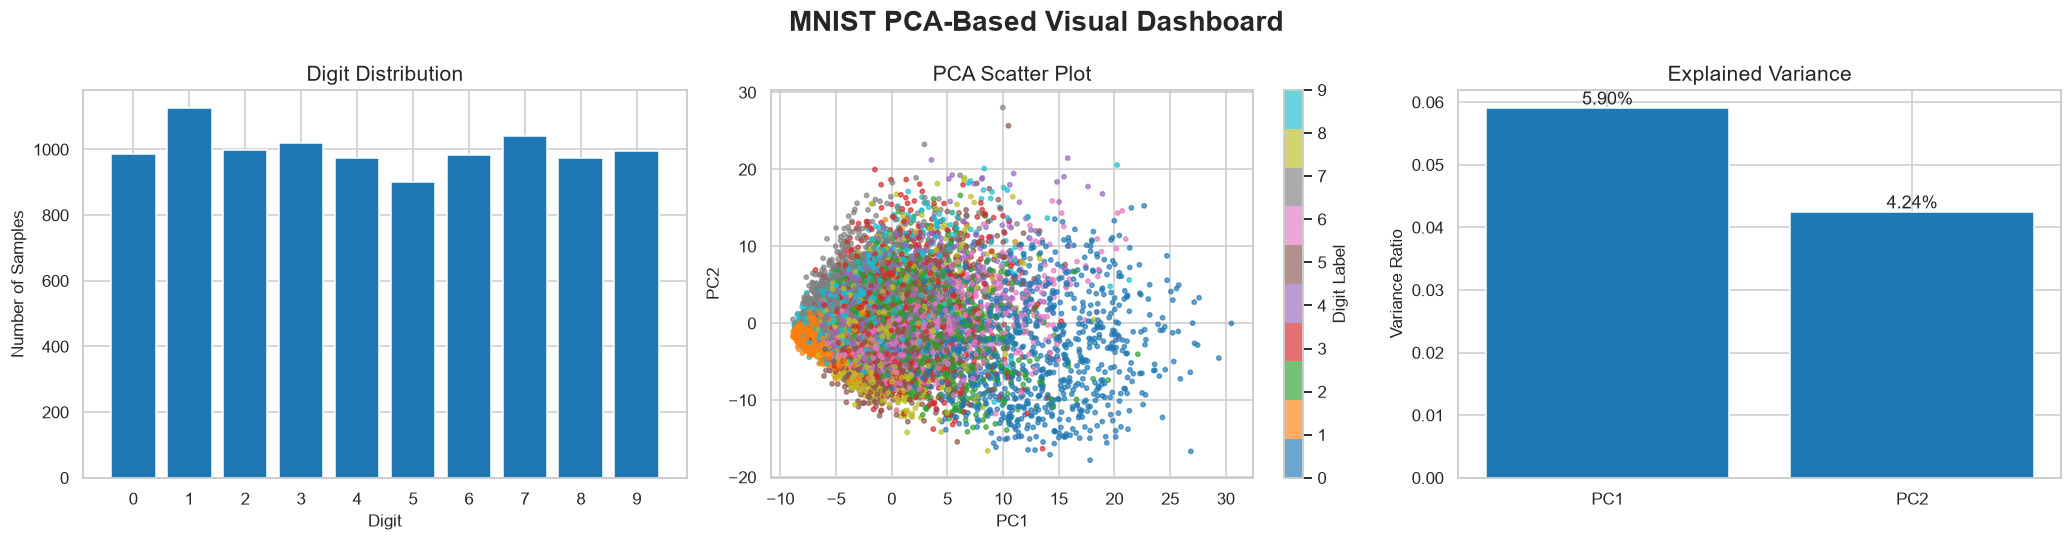

In [10]:
# ============================================================
# PCA VISUAL DASHBOARD
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Chart 1: Digit distribution
digit_counts = pd.Series(y_sample).value_counts().sort_index()

axes[0].bar(
    digit_counts.index,
    digit_counts.values
)

axes[0].set_title("Digit Distribution")
axes[0].set_xlabel("Digit")
axes[0].set_ylabel("Number of Samples")
axes[0].set_xticks(range(10))

# Chart 2: PCA scatter plot
sc = axes[1].scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Digit"],
    cmap="tab10",
    s=8,
    alpha=0.65
)

axes[1].set_title("PCA Scatter Plot")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

# Chart 3: Explained variance
axes[2].bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_
)

axes[2].set_title("Explained Variance")
axes[2].set_ylabel("Variance Ratio")

for i, value in enumerate(pca.explained_variance_ratio_):
    axes[2].text(
        i,
        value,
        f"{value:.2%}",
        ha="center",
        va="bottom"
    )

fig.colorbar(
    sc,
    ax=axes[1],
    label="Digit Label"
)

fig.suptitle(
    "MNIST PCA-Based Visual Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# PCA STATISTICAL SUMMARY
# ============================================================

total_variance = pca.explained_variance_ratio_.sum()

summary = pd.DataFrame({
    "Metric": [
        "Total Samples Analyzed",
        "Original Feature Count",
        "Reduced Feature Count",
        "Number of Digit Classes",
        "PC1 Explained Variance",
        "PC2 Explained Variance",
        "Total Variance Retained"
    ],
    "Value": [
        len(X_sample),
        X_sample.shape[1],
        X_pca.shape[1],
        len(np.unique(y_sample)),
        f"{pca.explained_variance_ratio_[0]:.4%}",
        f"{pca.explained_variance_ratio_[1]:.4%}",
        f"{total_variance:.4%}"
    ]
})

display(summary)

print("=" * 50)
print("PROJECT ANALYSIS")
print("=" * 50)

print(
    f"PCA reduced the dataset from "
    f"{X_sample.shape[1]} features to {X_pca.shape[1]} features."
)

print(
    f"The first two principal components retained "
    f"{total_variance:.2%} of the variance."
)

print(
    "The scatter plot provides a visual representation "
    "of digit similarities and differences."
)

,Metric,Value
0,Total Samples Analyzed,10000
1,Original Feature Count,784
2,Reduced Feature Count,2
3,Number of Digit Classes,10
4,PC1 Explained Variance,5.9004%
5,PC2 Explained Variance,4.2419%
6,Total Variance Retained,10.1423%


PROJECT ANALYSIS
PCA reduced the dataset from 784 features to 2 features.
The first two principal components retained 10.14% of the variance.
The scatter plot provides a visual representation of digit similarities and differences.


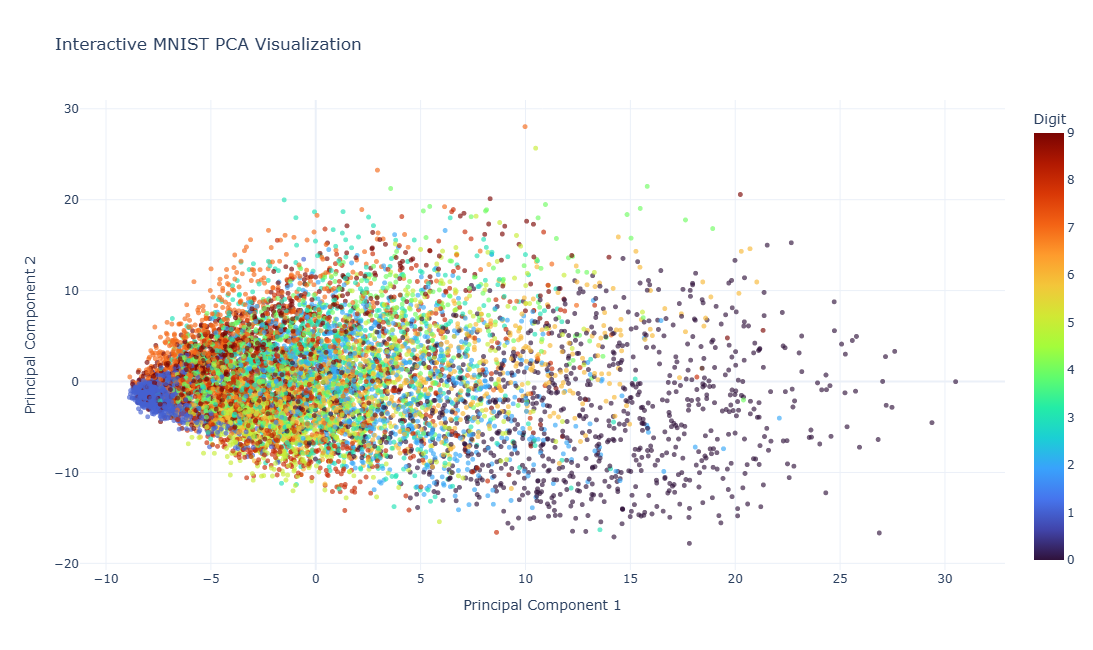

In [12]:
# ============================================================
# ADVANCED INTERACTIVE PCA VISUALIZATION
# ============================================================

import plotly.express as px

interactive_fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="Digit",
    color_continuous_scale="Turbo",
    hover_data={
        "Digit": True,
        "PC1": ":.3f",
        "PC2": ":.3f"
    },
    title="Interactive MNIST PCA Visualization"
)

interactive_fig.update_traces(
    marker=dict(size=5, opacity=0.65)
)

interactive_fig.update_layout(
    template="plotly_white",
    width=1000,
    height=650,
    xaxis_title="Principal Component 1",
    yaxis_title="Principal Component 2",
    legend_title="Digit Label"
)

interactive_fig.show()